Федосеева Анастасия
#  **Теория вероятностей**


# **1. Задачи на бумаге**

## **Задача 1.1. Случайная скидка**

Покупатель получает случайную скидку. Какая скидка выпадает и с какой вероятностью, показано в
таблице. Например, с вероятностью 0,60 скидки нет совсем, а с вероятностью 0,02 выпадает скидка
5000 рублей.
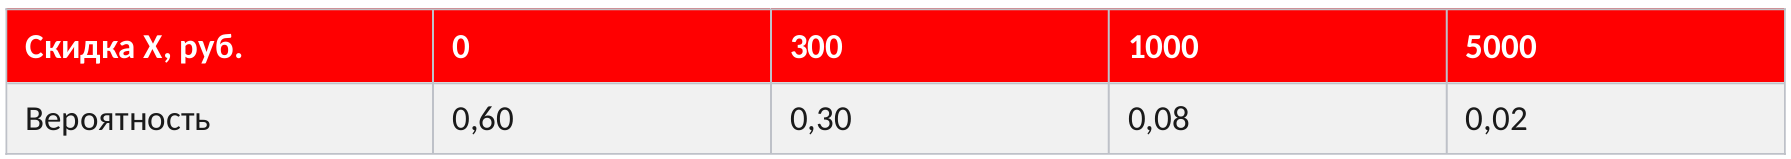
Что сделать:
*   Найти среднюю скидку, то есть математическое ожидание E[X].
*   Найти дисперсию скидки Var(X).

Матожидание дискретной величины:

E(X) = 0 * 0,60 + 300 * 0,3 + 1000 * 0,08 + 5000 * 0,02 = 270

Дисперсия:

Var(X) = E[(X − E[X])²] = 0² * 0,60 + 300² * 0,3 + 1000² * 0,08 + 5000² * 0,02 - 270² = 607000 - 72900 = 534100

Стандартное отклонение σ = √534 100 ≈ 731 руб.

Средняя скидка 270 руб., но разброс (σ ≈ 731 руб.) почти в 3 раза больше среднего. Его создаёт редкая скидка в 5000 руб.

## **Задача 1.2. Покупки за день**

Конверсия сайта 4%. За день на него зашли 200 человек, и каждый решает, купить или нет
независимо от других.
Что сделать:
*   Найти, сколько покупок в среднем бывает за такой день.
*   Найти стандартное отклонение числа покупок.

Клиенты независимы и у всех одна и та же вероятность покупки - значит это биномиальное распределение.

Среднее количества покупок за такой день - матожидание:

E(X) = 200 * 0,04 = 8

Дисперсия: Var(X) = n*p*(1 - p) = 200 * 0,04 * 0,96 = 7,68.

Стандартное отклонение: σ = √7,68 ≈ 2,77 покупки.

То есть в типичный день число покупок отличается от 8 примерно на 3.

## **Задача 1.3. Ожидание ответа в чате**

Ответ в онлайн-чате приходит через случайное время от 1 до 5 минут, и любое время в этом
промежутке одинаково вероятно. Это равномерное распределение.
Что сделать:
*   Найти среднее время ожидания.
*   Найти дисперсию времени ожидания.

Время X равномерно распределено на отрезке [1; 5], поэтому плотность постоянна и равна 1/(5 - 1) = 1/4 (проверка: площадь под плотностью 4 * 1/4 = 1). Время непрерывно, поэтому вместо суммы берём интеграл:

E[X] = ∫ x*f(x) dx от 1 до 5 = (1/4) * [x²/2] от 1 до 5 = (1/4) * (25 - 1)/2 = (1/4)*12 = 3 минуты

Для дисперсии нужен E[X²]:

E[X²] = ∫ x² * f(x) dx от 1 до 5 = (1/4) * [x³/3] от 1 до 5 = (1/4) * (125 - 1)/3 = (1/4) * (124/3) = 31/3

Var(X) = E[X²] - (E[X])² = 31/3 - 3² = 31/3 - 27/3 = 4/3 ≈ 1,33

Стандартное отклонение σ = √(4/3) ≈ 1,15 мин.

## **Задача 1.4. Какое это распределение?**

Что сделать: для каждой ситуации назвать подходящее распределение и в одном-двух предложениях объяснить почему.
*   а) Сколько соискателей из 500, открывших вакансию, откликнутся;
*   б) время работы сервера до сбоя, если сбои случаются случайно и не зависят от того, сколько
сервер уже проработал;
*   в) рост взрослого человека в большой случайной группе людей;
*   г) ежемесячный платёж по кредитной карте, если у большинства клиентов он небольшой, а у немногих очень большой.

а) Это биномиальное распределение. Каждый соискатель независимо от других откликается или нет с одной и той же вероятностью, а нас интересует число откликов, то есть сумма 500 таких величин.

б) Экспоненциальное - отрезок времени это непрерывная величина, время до сбоя не бывает отрицательным, и распределение будет скошено вправо, так как короткое время до сбоя встречается чаще длинного.

в) Рост взрослых в большой случайной группе людей представляет собой нормальное распределение. Рост взрослых людей даёт симметричный колокол: большинство около среднего, очень высокие и очень низкие встречаются редко и в равной мере.

г) Экспоненциальное, перекошенное вправо с длинным правым хвостом. Большинство платежей маленькие, а редкие огромные тянут хвост вправо. Платёж не бывает отрицательным, среднее получается больше медианы, симметричного колокола нет.

# **Симуляции в Python**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## **Задание 2.1. Нормальная выборка**

* Сгенерировать 5000 значений нормального распределения, например со средним 40 и стандартным отклонением 8.
* Построить гистограмму и нарисовать поверх неё теоретическую плотность.
*   Сравнить среднее и стандартное отклонение выборки с теми, что вы задали.





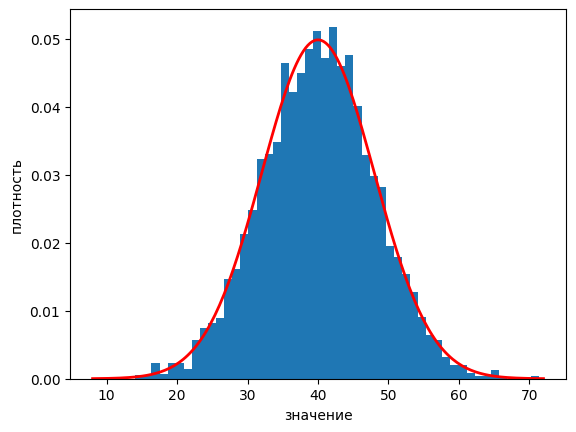

Среднее: выборка 40.04, задано 40
Стандартное отклонение: выборка 7.97, задано 8


In [2]:
np.random.seed(42)
mu, sigma = 40, 8
sample_norm = np.random.normal(mu, sigma, size=5000)

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)
plt.hist(sample_norm, bins=50, density=True)
plt.plot(x, stats.norm.pdf(x, mu, sigma), color='red', linewidth=2)
plt.xlabel('значение')
plt.ylabel('плотность')
plt.show()

print(f'Среднее: выборка {sample_norm.mean():.2f}, задано {mu}')
print(f'Стандартное отклонение: выборка {sample_norm.std():.2f}, задано {sigma}')

Среднее выборки (40,04) и стандартное отклонение (7,97) очень близки к заданным 40 и 8, а гистограмма повторяет теоретическую плотность. Небольшие отличия - случайность выборки: стандартная ошибка среднего при n = 5000 равна σ/√n = 8/√5000 ≈ 0,11, и отличие в 0,04 в неё укладывается.

## **Задание 2.2. Биномиальная выборка**

* Сгенерировать 5000 значений биномиального распределения, например n = 1000, p = 0,04.
* Построить гистограмму и нарисовать поверх неё теоретическую функцию вероятности.
* Сравнить среднее и стандартное отклонение выборки с теоретическими значениями.

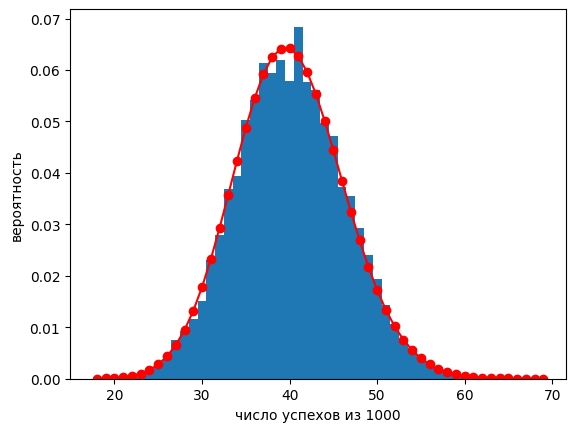

Среднее: выборка 40.20, теория n*p = 40.00
Стандартное отклонение: выборка 6.19, теория √(n*p*(1−p)) = 6.20


In [3]:
np.random.seed(42)

n, p = 1000, 0.04
sample_bin = np.random.binomial(n, p, size=5000)

k = np.arange(sample_bin.min(), sample_bin.max() + 1)
plt.hist(sample_bin, bins=k - 0.5, density=True)
plt.plot(k, stats.binom.pmf(k, n, p), 'o-', color='red')
plt.xlabel('число успехов из 1000')
plt.ylabel('вероятность')
plt.show()

theor_mean = n * p
theor_std = np.sqrt(n * p * (1 - p))
print(f'Среднее: выборка {sample_bin.mean():.2f}, теория n*p = {theor_mean:.2f}')
print(f'Стандартное отклонение: выборка {sample_bin.std():.2f}, теория √(n*p*(1−p)) = {theor_std:.2f}')

Теоретические значения: E[X] = n*p = 1000 * 0,04 = 40 и σ = √(1000 * 0,04*0,96) = √38,4 ≈ 6,20. В выборке получилось 40,20 и 6,19: стандартное отклонение совпало почти точно, а среднее выше теоретического на 0,2, это около 2 стандартных ошибок (σ/√n ≈ 6,2/√5000 ≈ 0,09), то есть в пределах случайности выборки. Точки теоретической функции вероятности ложатся на вершины столбиков, симуляция согласуется с формулой.

## **Задание 2.3. ЦПТ на экспоненциальном распределении**

* Сгенерировать выборку из 500 значений экспоненциального распределения и посчитать её среднее.
* Повторить это несколько тысяч раз.
* Построить гистограмму полученных средних и в двух-трёх предложениях описать, что на ней видно и почему.

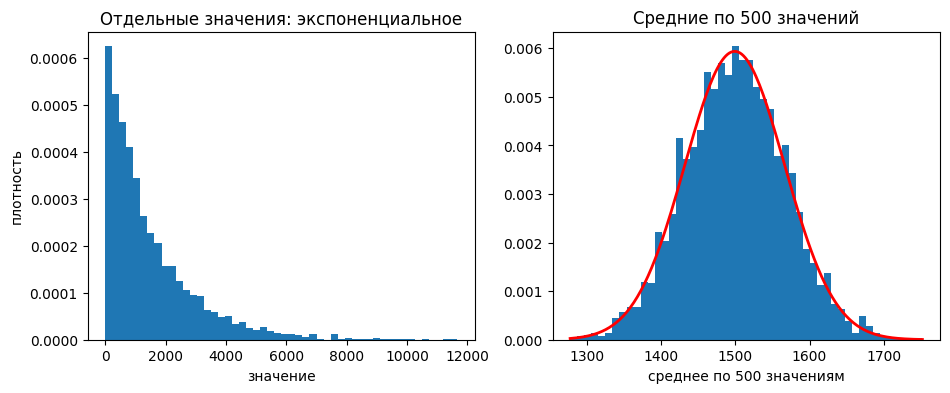

Одно наблюдение: μ ≈ 1499, σ ≈ 1502
Средние по 500: среднее 1500, станд. откл. 67.6
Теория по ЦПТ: среднее 1499, σ/√n = 67.2


In [4]:
np.random.seed(42)

n_per_day = 500
n_days = 3000

daily_means = np.array([
    np.random.exponential(scale=1500, size=n_per_day).mean()
    for _ in range(n_days)
])

single = np.random.exponential(scale=1500, size=200000)
mu1, sigma1 = single.mean(), single.std()
se = sigma1 / np.sqrt(n_per_day)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(single[:5000], bins=50, density=True)
axes[0].set_title('Отдельные значения: экспоненциальное')
axes[0].set_xlabel('значение')
axes[0].set_ylabel('плотность')

axes[1].hist(daily_means, bins=50, density=True)
xs = np.linspace(daily_means.min(), daily_means.max(), 200)
axes[1].plot(xs, stats.norm.pdf(xs, mu1, se), color='red', linewidth=2)
axes[1].set_title('Средние по 500 значений')
axes[1].set_xlabel('среднее по 500 значениям')

plt.show()

print(f'Одно наблюдение: μ ≈ {mu1:.0f}, σ ≈ {sigma1:.0f}')
print(f'Средние по 500: среднее {daily_means.mean():.0f}, станд. откл. {daily_means.std():.1f}')
print(f'Теория по ЦПТ: среднее {mu1:.0f}, σ/√n = {se:.1f}')

Хотя отдельные значения распределены экспоненциально и сильно скошены вправо, 3000 средних по 500 значений образуют симметричный колокол с центром около 1500. Так происходит по центральной предельной теореме: среднее большого числа независимых одинаково распределённых величин с конечной дисперсией приближённо нормально, и колокол из симуляции (станд. откл. 67,6) почти совпадает с теоретическим σ/√n = 1502/√500 ≈ 67,2. Колокол при этом намного уже разброса отдельных значений, усреднение даёт нормальность и точность.

# **3. Мини-кейс про кнопку**

Кнопку «Откликнуться» перекрасили и сравнили две группы соискателей.
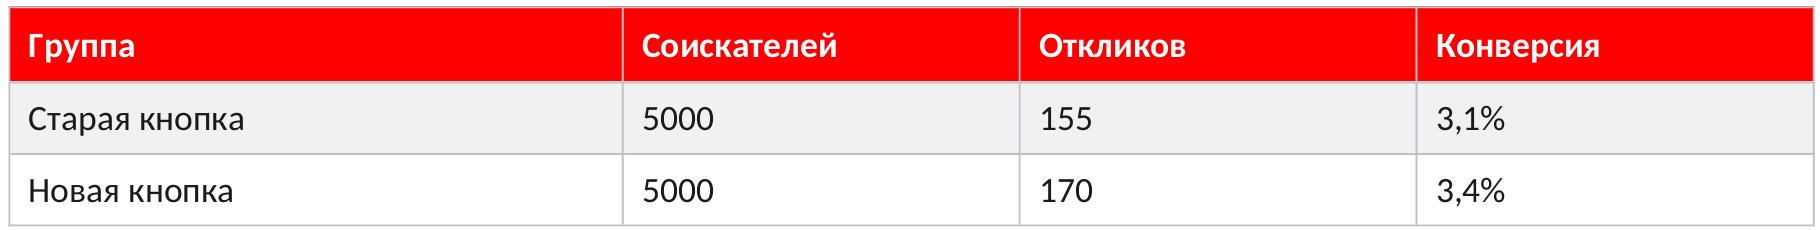

Разница конверсий 0,3 п.п. Нужно понять, это эффект новой кнопки или случайность.

## **Задание 3.1. Посчитать по формуле**

* Для каждой группы посчитать, насколько может случайно ошибаться оценка конверсии (стандартную ошибку).
*   Сравнить ошибку с разницей 0,3 п.п.
*   Написать предварительный вывод.



Один соискатель - величина Бернулли (X = 1, если откликнулся), поэтому Var(X) = p(1 - p). Вероятность p оцениваем конверсией по выборке p̂ = k/n. Стандартное отклонение одного наблюдения σ = √(p̂(1 - p̂)), стандартная ошибка конверсии SE = σ/√n. В обеих группах n = 5000, √5000 ≈ 70,71.

Старая кнопка:

p̂ = 155/5000 = 0,031

σ² = p̂(1 - p̂) = 0,031 * 0,969 = 0,030039

σ = √0,030039 ≈ 0,1733

SE = σ/√n = 0,1733/70,71 ≈ 0,00245 = 0,245 п.п.

Новая кнопка:

p̂ = 170/5000 = 0,034

σ² = p̂(1 - p̂) = 0,034 * 0,966 = 0,032844, σ = √0,032844 ≈ 0,1812

SE = σ/√n = 0,1812/70,71 ≈ 0,00256 = 0,256 п.п.

Сравнение с разницей. Разница конверсий 3,4% - 3,1% = 0,3 п.п. Она лишь примерно на 20% больше ошибки одной группы (0,3/0,25 ≈ 1,2).

Но сравниваются две оценки, и у каждой своя ошибка. Группы независимы, а дисперсии независимых величин складываются, поэтому

Var(разницы) = SE₁² + SE₂² = 0,00245² + 0,00256² ≈ 0,0000060 + 0,0000066 = 0,0000126

SE разницы = √0,0000126 ≈ 0,00355 = 0,355 п.п.

Разница 0,3 п.п. меньше этой ошибки: 0,3/0,355 ≈ 0,85 стандартной ошибки.

Предварительный вывод: разница сопоставима с обычной случайной ошибкой оценки, поэтому по этим данным нельзя отличить эффект новой кнопки от шума и нельзя утверждать, что она повысила конверсию. Это не значит, что эффекта нет: для такого маленького роста данных мало.

## **Задание 3.2. Проверить симуляцией**

*   Предположить, что кнопка ни на что не влияет и конверсия в обеих группах одинаковая.
*   Много раз смоделировать две такие группы по 5000 соискателей и посчитать разницу их конверсий
*   Построить гистограмму разниц и посчитать, как часто случайно получается 0,3 п.п. или больше.
*   Ответить: шум это или эффект


Если кнопка ни на что не влияет, у всех 10 000 соискателей одна и та же вероятность отклика. Оцениваем её по обеим группам вместе: p₀ = (155 + 170)/10 000 = 0,0325. В каждой группе n = 5000 независимых соискателей, поэтому число откликов в ней биномиально: Binomial(5000; 0,0325). Моделируем две такие группы 100 000 раз и каждый раз считаем разницу конверсий новой и старой.

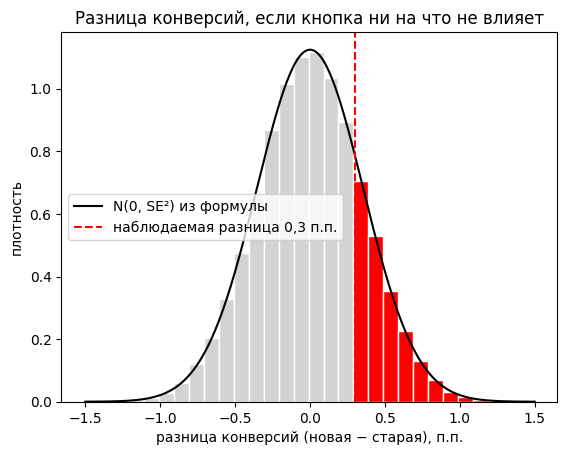

Разница >= 0,3 п.п. в пользу новой кнопки: 20.7% экспериментов
Разница >= 0,3 п.п. в любую сторону: 41.3% экспериментов
Станд. откл. разницы в симуляции: 0.354 п.п.


In [10]:
np.random.seed(42)

n = 5000
p0 = (155 + 170) / (2 * n)
n_sim = 100000

old = np.random.binomial(n, p0, size=n_sim)
new = np.random.binomial(n, p0, size=n_sim)
diff_cnt = new - old
diff_pp = diff_cnt / n * 100

edges = np.arange(-1.51, 1.52, 0.1)
fig, ax = plt.subplots()
heights, bins, patches = ax.hist(diff_pp, bins=edges, density=True, color='lightgray', edgecolor='white')
for patch, left in zip(patches, bins[:-1]):
    if left > 0.29:
        patch.set_facecolor('red')

xs = np.linspace(-1.5, 1.5, 300)
ax.plot(xs, stats.norm.pdf(xs, 0, np.sqrt(2 * p0 * (1 - p0) / n) * 100), color='black', linewidth=1.5, label='N(0, SE²) из формулы')
ax.axvline(0.3, color='red', linestyle='--', label='наблюдаемая разница 0,3 п.п.')
ax.set_xlabel('разница конверсий (новая − старая), п.п.')
ax.set_ylabel('плотность')
ax.set_title('Разница конверсий, если кнопка ни на что не влияет')
ax.legend()
plt.show()

share = (diff_cnt >= 15).mean()
share_abs = (np.abs(diff_cnt) >= 15).mean()
print(f'Разница >= 0,3 п.п. в пользу новой кнопки: {share:.1%} экспериментов')
print(f'Разница >= 0,3 п.п. в любую сторону: {share_abs:.1%} экспериментов')
print(f'Станд. откл. разницы в симуляции: {diff_pp.std():.3f} п.п.')

## **Задание 3.3. Выбросы во времени сессий**

Время сессий за день, в минутах: 3, 4, 4, 5, 5, 6, 6, 7, 8, 52.
*   Найти выбросы правилом трёх сигм.
*   Найти выбросы по перцентилям.
*   Сравнить результаты и объяснить, какой способ сработал лучше и почему.

In [12]:
x = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

# Правило трёх сигм
mean, std = x.mean(), x.std(ddof=1)
low_3s, up_3s = mean - 3 * std, mean + 3 * std
out_3s = x[(x < low_3s) | (x > up_3s)]
print(f'Три сигмы: среднее {mean:.1f}, σ {std:.1f}, границы [{low_3s:.1f}; {up_3s:.1f}], выбросы: {out_3s}')

# Перцентили
p25, p75 = np.percentile(x, [25, 75])
iqr = p75 - p25
low_pct, up_pct = p25 - 1.5 * iqr, p75 + 1.5 * iqr
out_pct = x[(x < low_pct) | (x > up_pct)]
print(f'Перцентили: 25-й {p25:.2f}, 75-й {p75:.2f}, границы [{low_pct:.2f}; {up_pct:.2f}], выбросы: {out_pct}')

# что было бы без значения 52
x_clean = x[x != 52]
print(f'Без 52: среднее {x_clean.mean():.1f}, σ {x_clean.std(ddof=1):.1f}, '
      f'верхняя граница трёх сигм {x_clean.mean() + 3 * x_clean.std(ddof=1):.1f}')
print(f'Медиана: с 52 - {np.median(x):.1f}, без 52 - {np.median(x_clean):.1f}')

Три сигмы: среднее 10.0, σ 14.8, границы [-34.5; 54.5], выбросы: []
Перцентили: 25-й 4.25, 75-й 6.75, границы [0.50; 10.50], выбросы: [52]
Без 52: среднее 5.3, σ 1.6, верхняя граница трёх сигм 10.1
Медиана: с 52 - 5.5, без 52 - 5.0


Правило трёх сигм выбросов не нашло: среднее 10,0, σ ≈ 14,8, границы [-34,5; 54,5], и значение 52 внутри.

Перцентили: 25-й = 4,25, 75-й = 6,75, граница сверху 6,75 + 1,5 * 2,5 = 10,5. Выброс один: 52, остальные значения внутри границ.

Сравнение: Лучше сработали перцентили. Правило трёх сигм подвело потому, что выброс сам участвует в расчёте. Значение 52 подняло среднее с 5,3 до 10,0 и раздуло σ с 1,6 до 14,8, поэтому граница ушла дальше самого выброса (без 52 она была бы около 10,1, и 52 вылетело бы с огромным запасом). Перцентили зависят от порядка значений, а не от их величины. К тому же время сессий скошено вправо, для таких данных лучше опираться на перцентили.

Найденное значение не нужно сразу удалять. Сначала стоит выяснить, откуда оно взялось (забытая вкладка, бот, сбой или настоящий долгий визит). В случае, если это ошибка, её необходимо исправить или удалить, настоящее значение нужно рассмотреть отдельно.